# Part 3: Model and Simulation
---
## 1. Objective and Roadmap
A leveraged ETF such as TQQQ aims to deliver 3 times the daily return of QQQ. Its risk over one month cannot be read from history alone, because history gives only one path. To measure risk (VaR and ES in Part 4), we need thousands of possible future paths. This part builds them.

## 2. Data and Setup
Data: `data/processed/clean_returns.csv` from the group's data part.

We model QQQ and not TQQQ because TQQQ's return is QQQ's return with a known leverage rule. So we model the market risk (QQQ) first, and add the leverage rule afterwards with an engine (Section 6). This keeps the two sources of risk separate. We work with daily log returns in %.

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from arch import arch_model
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3})

In [3]:
# Settings
SEED = 42
N_PATHS = 10_000      # number of simulated paths
HORIZON = 21          # trading days in one month
LEVERAGE = 3
DAYS = 252            # trading days per year

ROOT = next(p for p in [".", "..", "../.."] if os.path.exists(f"{p}/data/processed/clean_returns.csv"))
OUT = f"{ROOT}/outputs/part3"
os.makedirs(f"{OUT}/figures", exist_ok=True)
os.makedirs(f"{OUT}/tables", exist_ok=True)

def show(name):
    """Tidy the layout, save the current figure, and display it."""
    plt.tight_layout()
    plt.savefig(f"{OUT}/figures/{name}.png", dpi=200)
    plt.show()

In [4]:
df = pd.read_csv(f"{ROOT}/data/processed/clean_returns.csv", parse_dates=["date"], index_col="date")
r = df["qqq_log_return"] * 100                       # QQQ daily log return, in %

print(f"Sample: {r.index[0].date()} to {r.index[-1].date()} ({len(r)} trading days)")
print(f"Daily mean {r.mean():.3f}%  |  daily std {r.std():.3f}%  |  annualized volatility {r.std() * np.sqrt(DAYS):.1f}%")

Sample: 2019-01-03 to 2026-11-20 (1983 trading days)
Daily mean 0.071%  |  daily std 1.521%  |  annualized volatility 24.1%


## 3. What do QQQ returns look like?
Before choosing a model, we check whether a simple model (constant risk, Normal returns) would be reasonable.

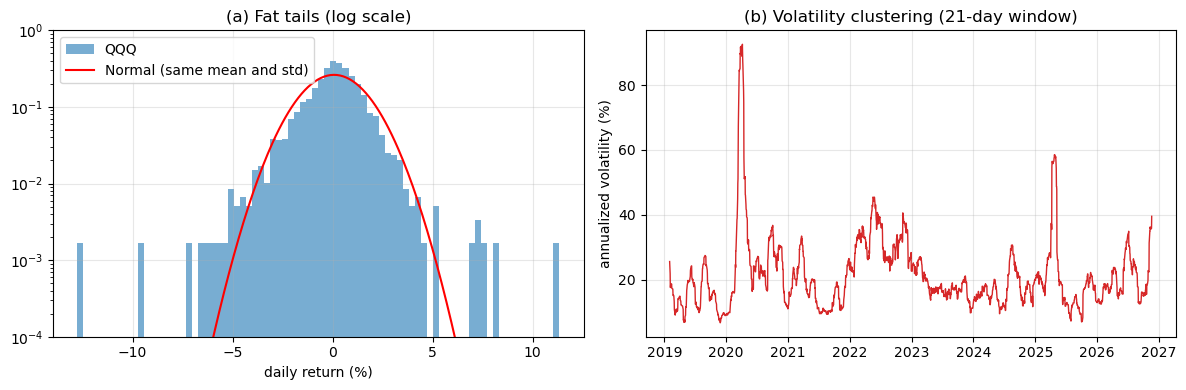

Skewness: -0.41   |   Excess kurtosis: 7.08  (Normal = 0)
ARCH-LM test p-value: 6.5e-80  (p < 0.05 means volatility clustering)


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# (a) Tails: real distribution vs a Normal with the same mean and std
x = np.linspace(r.min(), r.max(), 300)
ax[0].hist(r, bins=80, density=True, alpha=0.6, label="QQQ")
ax[0].plot(x, stats.norm.pdf(x, r.mean(), r.std()), "r", label="Normal (same mean and std)")
ax[0].set(yscale="log", ylim=(1e-4, 1), xlabel="daily return (%)", title="(a) Fat tails (log scale)")
ax[0].legend()

# (b) Volatility over time
ax[1].plot(r.rolling(21).std() * np.sqrt(DAYS), color="tab:red", lw=1)
ax[1].set(ylabel="annualized volatility (%)", title="(b) Volatility clustering (21-day window)")
show("fig1_qqq_returns")

print(f"Skewness: {stats.skew(r):.2f}   |   Excess kurtosis: {stats.kurtosis(r):.2f}  (Normal = 0)")
print(f"ARCH-LM test p-value: {het_arch(r - r.mean(), nlags=10)[1]:.1e}  (p < 0.05 means volatility clustering)")

**Analysis**
- **Fat tails.** Excess kurtosis is 7.08, while a Normal distribution has 0. In panel (a), the real tails lie far above the Normal curve, so extreme days are much more common than a Normal model says. The skewness of −0.41 also shows that big falls are larger than big rises.
- **Volatility clustering.** In panel (b), volatility is not constant: calm periods and turbulent periods come in groups (2020 and April 2025). The ARCH-LM test confirms that where as p < 0.05 means volatility clustering.

Therefore, a suitable model must let volatility change over time and must allow extreme shocks. Both matter more for a 3x ETF, because leverage magnifies them.

## 4. The Models
Every daily return can be split into an expected part and a random shock. The models differ in how they describe the size of the shock. We use two models (GBM and GARCH-t) and one model-free check (the historical bootstrap).

| Method | Type | Role |
|---|---|---|
| **GBM** | Model | Simple benchmark |
| **GARCH(1,1)-t** | Model | Main model |
| **Historical bootstrap** | No model | Reality check |

### 4.1 Model A: GBM (benchmark)
$$r_t = \mu + \sigma\, z_t, \qquad z_t \sim N(0,1)$$

Every day, the return is the same average plus a random shock. The shock always comes from the same bell curve, so **risk never changes**. This means the price follows a Geometric Brownian Motion (GBM), the classic model behind the Black-Scholes formula.

### 4.2 Model B: GARCH(1,1)-t (main model)
$$r_t = \mu + \varepsilon_t,\quad \varepsilon_t = \sigma_t z_t,\quad \sigma_t^2 = \omega + \alpha\,\varepsilon_{t-1}^2 + \beta\,\sigma_{t-1}^2,\quad z_t \sim \text{Student-}t(\nu)$$


### 4.1 Model A: GBM (benchmark)
$$r_t = \mu + \sigma\, z_t, \qquad z_t \sim N(0,1)$$

Each daily log return is a constant mean $\mu$ plus a Normal shock with constant standard deviation $\sigma$, so risk does not change over time. The implied price process is a Geometric Brownian Motion, the model underlying the Black-Scholes formula.

It is the standard simple model, but as Section 3 showed that QQQ volatility varies over time and its tails are heavier than Normal. GBM allows for neither.

### 4.2 Model B: GARCH(1,1)-t (main model)
$$r_t = \mu + \varepsilon_t,\quad \varepsilon_t = \sigma_t z_t,\quad \sigma_t^2 = \omega + \alpha\,\varepsilon_{t-1}^2 + \beta\,\sigma_{t-1}^2,\quad z_t \sim \text{Student-}t(\nu)$$

Here $\varepsilon_t$ is the unexpected part of the return and $\sigma_t^2$ is its variance, which is updated every day. The variance equals a base level $\omega$, plus a reaction $\alpha$ to the previous day's shock, plus a carry-over $\beta$ of the previous day's variance. A large shock therefore raises the next day's variance, and a high $\beta$ makes the increase fade slowly, so large movements tend to be followed by large movements (volatility clustering). The shocks follow a Student-t distribution with $\nu$ degrees of freedom, which has heavier tails than the Normal, and a smaller $\nu$ means heavier tails.

It captures both features in Section 3, volatility clustering (through $\sigma_t^2$) and fat tails (through the t distribution). It can also start a simulation from the **current** volatility, which GBM cannot do. However, it is more complex and symmetric: shocks of equal size and opposite sign have the same effect on variance, whereas negative shocks usually raise volatility more in practice.

### 4.3 Method C: Historical bootstrap (check)
There is no parametric form. For each simulated day, one observed QQQ daily return is drawn at random with replacement, and 21 draws form one simulated month.

It makes no distributional assumption, so serves as a model-free check.

Section 5 estimates GBM and GARCH-t and tests which describes QQQ returns better.

## 5. Fit the Models
### 5.1 Estimation
GBM only needs the mean and the standard deviation. For GARCH-t we first remove the mean, so that both models share the same drift and differ only in how they treat risk.

In [6]:
# Model A: GBM (constant mean and volatility)
mu, sigma = r.mean(), r.std()

# Model B: GARCH(1,1) with Student-t shocks, fitted on demeaned returns
demeaned = r - mu
garch = arch_model(demeaned, mean="Zero", vol="GARCH", p=1, q=1, dist="t").fit(disp="off")
omega, alpha, beta, nu = garch.params[["omega", "alpha[1]", "beta[1]", "nu"]]

params_table = pd.DataFrame({"estimate": garch.params, "std err": garch.std_err, "p-value": garch.pvalues}).round(4)
display(params_table)

persistence = alpha + beta
half_life = np.log(0.5) / np.log(persistence)       # days for a volatility spike to fade by half
print(f"Persistence (alpha + beta) = {persistence:.3f}   |   half-life of a volatility shock = {half_life:.0f} trading days")

,estimate,std err,p-value
omega,0.0474,0.0133,0.0004
alpha[1],0.1284,0.0175,0.0000
beta[1],0.8564,0.0167,0.0000
nu,7.0176,1.0538,0.0000


Persistence (alpha + beta) = 0.985   |   half-life of a volatility shock = 45 trading days



All GARCH parameters are statistically significant (p < 0.01). Volatility reacts moderately to new shocks ($\alpha$ = 0.13) but has a strong memory ($\beta$ = 0.86), with persistence of 0.985. This means volatility shocks fade slowly, taking around 45 trading days to halve. The estimated $\nu$ = 7.0 also suggests heavier tails than a Normal distribution, meaning extreme returns are more likely. Next, we test whether GARCH-t captures risks that GBM misses.

### 5.2 Diagnostics
If a model works, the **standardized residuals** (shocks divided by the model's own daily volatility) should show no volatility clustering. A **small p-value means the pattern is still there**.

In [ ]:
resid = garch.std_resid 
gbm = arch_model(demeaned, mean="Zero", vol="Constant", dist="normal").fit(disp="off")  

def clustering_pvalues(x):
    return {"Ljung-Box on squared series": acorr_ljungbox(x**2, lags=[10])["lb_pvalue"].iloc[0],
            "ARCH-LM": het_arch(x, nlags=10)[1]}

diag_table = pd.DataFrame({"GBM (raw returns)": clustering_pvalues(demeaned), "GARCH-t (residuals)": clustering_pvalues(resid)})
fit_table = pd.DataFrame({"GBM": [gbm.loglikelihood, gbm.aic, gbm.bic], "GARCH-t": [garch.loglikelihood, garch.aic, garch.bic]},
                         index=["Log-likelihood", "AIC", "BIC"]).round(1)
display(diag_table.map(lambda p: f"{p:.3f}"))
display(fit_table)
print(f"Excess kurtosis: raw returns = {stats.kurtosis(demeaned):.2f}  ->  GARCH-t residuals = {stats.kurtosis(resid):.2f}")

,GBM (raw returns),GARCH-t (residuals)
Ljung-Box on squared series,0.000,0.216
ARCH-LM,0.000,0.156


,GBM,GARCH-t
Log-likelihood,-3644.3,-3306.8
AIC,7290.6,6621.6
BIC,7296.2,6643.9


Excess kurtosis: raw returns = 7.08  ->  GARCH-t residuals = 1.59


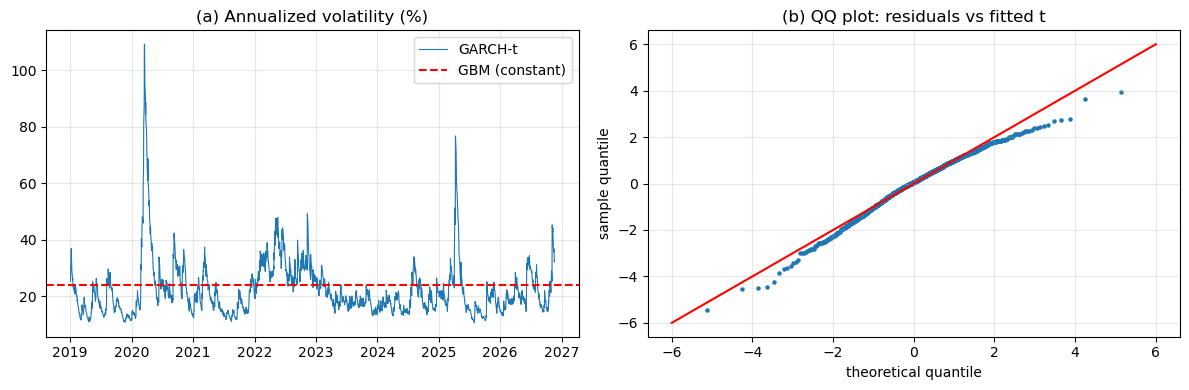

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# (a) GARCH-t volatility moves over time, GBM stays constant
ax[0].plot(garch.conditional_volatility * np.sqrt(DAYS), lw=0.8, label="GARCH-t")
ax[0].axhline(sigma * np.sqrt(DAYS), color="r", ls="--", label="GBM (constant)")
ax[0].set(title="(a) Annualized volatility (%)"); ax[0].legend()

# (b) QQ plot: are the residuals consistent with the fitted t distribution?
n = len(resid)
probs = (np.arange(1, n + 1) - 0.5) / n
t_quantiles = stats.t.ppf(probs, nu) * np.sqrt((nu - 2) / nu)      # t scaled to variance 1
ax[1].scatter(t_quantiles, np.sort(resid), s=5)
ax[1].plot([-6, 6], [-6, 6], "r")
ax[1].set(title="(b) QQ plot: residuals vs fitted t", xlabel="theoretical quantile", ylabel="sample quantile")
show("fig2_garch_diagnostics")

**Analysis**

**Volatility clustering.** A small p-value in the Ljung-Box and ARCH-LM tests means that clustering remains. For GBM both p-values are 0.000, because constant volatility leaves the clustering unexplained. For the GARCH-t residuals they are 0.216 and 0.156, both above 0.05, so no clustering remains. Panel (a) shows that GBM uses a single level of about 24% a year, while GARCH-t volatility follows the data, with peaks in 2020 and April 2025.

**Model fit.** GARCH-t also fits better: its log-likelihood is higher, meaning the observed data are more likely under the model. Its AIC and BIC are lower. Both criteria combine fit with a penalty for the number of parameters, so a lower value means a better trade-off between fit and complexity. GARCH-t has four parameters against one for GBM and still scores lower, so the improvement is not due to added flexibility alone.

**Fat tails.** Excess kurtosis falls from 7.08 to 1.59 for the standardized residuals, so most of the fat tails come from time-varying volatility. The QQ plot shows that the residuals follow the fitted t distribution closely in the centre, but the left tail is slightly heavier and the right tail slightly lighter than the t, because the symmetric t cannot capture the negative skew in QQQ returns.

Next, we build the engine that converts QQQ returns into 3x ETF returns.

## 6. Daily Rebalancing Engine
A leveraged ETF is where each day it targets 3 times that day's QQQ return, and then resets its exposure. Because of this reset, the return over several days is not 3 times QQQ's multi-day return. The result depends on the path.

The models in Section 5 give QQQ returns. The engine converts each simulated QQQ path into a 3x ETF path, using the same rule as the real fund:

$$R^{3x}_t = 3 \times R^{QQQ}_t - c, \qquad V_t = V_{t-1}\,(1 + R^{3x}_t)$$

where $R$ is the simple return, $c$ is the daily cost and $V_t$ is the value of $1 invested. 

The models give log returns, so the engine first converts them: $R = e^{r} - 1$. The leverage is applied to the daily simple return, and then the results are compounded.

In [9]:
def leveraged_nav(log_ret_pct, leverage=LEVERAGE, cost=0.0):
    """Convert QQQ daily log returns (%) into the value of a daily-reset leveraged ETF, starting at 1."""
    simple = np.exp(np.asarray(log_ret_pct) / 100) - 1          # step 1: log return -> simple return
    daily = np.maximum(leverage * simple - cost, -1)             # step 2: apply leverage and cost (cannot lose more than 100%)
    return np.cumprod(1 + daily, axis=-1)                        # step 3: compound every day

# Example: QQQ goes +10%, then -10%
example = np.log([1.10, 0.90]) * 100
print(f"QQQ (1x):             {1.10 * 0.90 - 1:+.1%}")
print(f"Naive '3 x QQQ':      {3 * (1.10 * 0.90 - 1):+.1%}")
print(f"Daily-reset 3x ETF:   {leveraged_nav(example)[-1] - 1:+.1%}   (= 1.30 x 0.70 - 1)")

QQQ (1x):             -1.0%
Naive '3 x QQQ':      -3.0%
Daily-reset 3x ETF:   -9.0%   (= 1.30 x 0.70 - 1)


QQQ loses 1% over the two days. A naive "3x" would suggest -3%, but the daily-reset ETF loses 9%. It gains 30% and then loses 30% of a larger base. This is volatility decay where the larger the daily swings, the more the 3x ETF falls behind 3 times QQQ's return.

Next, we test whether this engine reproduces a real product.

## 7. Does the Engine Reproduce Real TQQQ?

We feed the real QQQ returns into the engine and compare the result with real TQQQ. The engine needs the daily cost $c$, which we estimate as the average daily gap between TQQQ and 3 times QQQ.

Daily cost c = 0.035%  (about 8.7% per year)
Correlation of daily returns, TQQQ vs 3 x QQQ: 0.9991


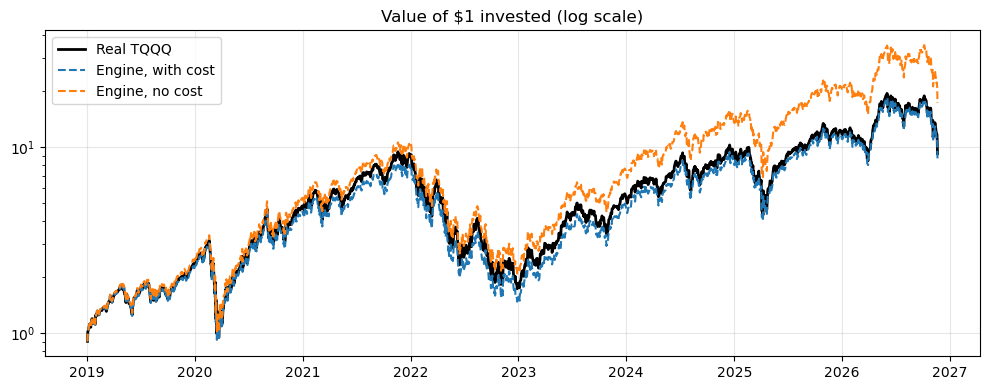

Final value of $1:  real TQQQ 9.2  |  engine with cost 8.7  |  engine no cost 17.3


In [10]:
cost = (LEVERAGE * df["qqq_simple_return"] - df["tqqq_simple_return"]).mean()
print(f"Daily cost c = {cost * 100:.3f}%  (about {cost * DAYS * 100:.1f}% per year)")
print(f"Correlation of daily returns, TQQQ vs 3 x QQQ: {np.corrcoef(df['tqqq_simple_return'], LEVERAGE * df['qqq_simple_return'])[0, 1]:.4f}")

real_tqqq   = (1 + df["tqqq_simple_return"]).cumprod()
engine_cost = pd.Series(leveraged_nav(r.values, cost=cost), index=r.index)
engine_free = pd.Series(leveraged_nav(r.values), index=r.index)

plt.plot(real_tqqq, "k", lw=2, label="Real TQQQ")
plt.plot(engine_cost, "--", label="Engine, with cost")
plt.plot(engine_free, "--", label="Engine, no cost")
plt.yscale("log"); plt.title("Value of $1 invested (log scale)"); plt.legend()
show("fig3_engine_vs_tqqq")
print(f"Final value of $1:  real TQQQ {real_tqqq.iloc[-1]:.1f}  |  engine with cost {engine_cost.iloc[-1]:.1f}  |  engine no cost {engine_free.iloc[-1]:.1f}")

The daily returns of TQQQ and 3 times QQQ have a correlation of 0.9991, so the daily-reset rule is correct.

Real TQQQ falls behind the ideal 3x by about 8.7% per year (fees, financing and tracking). Without this cost, the engine ends at 17.3, almost double the real value (9.2). With the cost, it ends at 8.7, close to the real TQQQ.

We therefore use this cost in all simulations.

Note: the cost is estimated over the whole sample and kept constant. In reality it moves with interest rates, so this is a simplification.